In [ ]:
# Forecast of products demand based on M5 dataset

In [24]:
%load_ext autoreload
%autoreload 2

In [36]:
from catboost import CatBoostRegressor

In [27]:
import pandas as pd
import numpy as np
from pathlib import Path
from catboost import CatBoostRegressor
from src.data.catboost_config import run_catboost_experiment
import gc
from sklearn.metrics import mean_absolute_error, mean_squared_error


from src.data.load_data import load_data, prepare_calendar
from src.data.build_features import build_features

from src.data.load_data import load_data, prepare_calendar

In [2]:
data_path = "../data/m5"


sales, calendar, prices = load_data(data_path)
calendar = prepare_calendar(calendar)

df = build_features(
    sales=sales,
    calendar=calendar,
    prices=prices,
)
# nonzero_days_14 — число дней с ненулевыми продажами за последние 14 дней.
# nonzero_rate_14 — доля дней с ненулевыми продажами.
# avg_positive_demand_14 — средний объём продаж в дни с положительным спросом.
# adi_14 — средний интервал между днями с ненулевыми продажами.
# demand_regime_14 — классификация спроса на intermittent, regular или unknown.
print(df.shape)
print(df.head())
print(df.columns)

(58327370, 40)
       item_id  dept_id cat_id store_id state_id    d  sales       date  \
0  FOODS_1_001  FOODS_1  FOODS     CA_1       CA  d_1      3 2011-01-29   
1  FOODS_1_001  FOODS_1  FOODS     CA_1       CA  d_2      0 2011-01-30   
2  FOODS_1_001  FOODS_1  FOODS     CA_1       CA  d_3      0 2011-01-31   
3  FOODS_1_001  FOODS_1  FOODS     CA_1       CA  d_4      1 2011-02-01   
4  FOODS_1_001  FOODS_1  FOODS     CA_1       CA  d_5      4 2011-02-02   

   wm_yr_wk  sell_price  ...  history_days_14  nonzero_rate_14  \
0     11101         2.0  ...              0.0              NaN   
1     11101         2.0  ...              1.0         1.000000   
2     11101         2.0  ...              2.0         0.500000   
3     11101         2.0  ...              3.0         0.333333   
4     11101         2.0  ...              4.0         0.500000   

   avg_positive_demand_14 adi_14 demand_regime_14 price_lag_1 price_median_7  \
0                     NaN    NaN          unknown        

In [19]:
from catboost import CatBoostRegressor

## We finished with features taken into account. Starting to build seasonal naive baseline

In [3]:
from src.data.split_data import split_data

train_df, validation_df, test_df, train_window = split_data(df)

print("Train:", train_df["date"].min(), "—", train_df["date"].max())
print("Validation:", validation_df["date"].min(), "—", validation_df["date"].max())
print("Test:", test_df["date"].min(), "—", test_df["date"].max())
print("Train window:", train_window["date"].min(), "—", train_window["date"].max())

Train: 2011-01-29 00:00:00 — 2016-03-27 00:00:00
Validation: 2016-03-01 00:00:00 — 2016-03-27 00:00:00
Test: 2016-03-28 00:00:00 — 2016-04-24 00:00:00
Train window: 2015-11-04 00:00:00 — 2016-02-29 00:00:00


In [5]:
# Определяем категориальные признаки
cat_features = [
    "item_id",
    "dept_id",
    "store_id",
    "event_name_1",
    "event_type_1",
    "demand_regime_14",
]

# Определяем числовые признаки
num_features = [
    "wday",
    "month",
    "year",
    "week_of_year",
    "day_of_month",
    "snap_CA",
    "snap_TX",
    "snap_WI",
    "sell_price",
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28",
    "rolling_std_28",
    "price_lag_1",
    "price_median_7",
    "price_median_28",
    "price_ratio_1",
    "price_ratio_28",
    "nonzero_days_14",
    "history_days_14",
    "nonzero_rate_14",
    "avg_positive_demand_14",
    "adi_14",
]

feature_cols = cat_features + num_features

# Проверяем соответствие признаков датафрейму
df_columns = set(df.columns)
feature_set = set(feature_cols)


missing_features = sorted(feature_set - df_columns)
extra_columns = sorted(
    df_columns - feature_set
    - {
        "sales", "date", "d", "wm_yr_wk",
        "cat_id", "state_id", "event_name_2", "event_type_2",
    }
)

if missing_features or extra_columns:
    if missing_features:
        print("Не хватает признаков:", missing_features)
    if extra_columns:
        print("Лишние колонки в датафрейме:", extra_columns)

    raise ValueError("Проверь состав признаков перед обучением модели.")

print("Все признаки соответствуют датафрейму. Можно продолжать.")

Все признаки соответствуют датафрейму. Можно продолжать.


In [6]:
# Подготавливаем данные для модели
X_train = train_window[feature_cols]
y_train = train_window["sales"]

X_val = validation_df[feature_cols]
y_val = validation_df["sales"]

X_test = test_df[feature_cols]
y_test = test_df["sales"]

In [13]:
# Seasonal Naive baseline: продажи за 7 дней до прогнозируемой даты
val_pred_baseline = validation_df["lag_7"].to_numpy()

evaluate_model(
    "Baseline: lag_7",
    y_val,
    val_pred_baseline,
)

Model: Baseline: lag_7
MAE:   1.2055
RMSE:  2.7634
WAPE:  87.14%


{'model': 'Baseline: lag_7',
 'MAE': 1.2054784203685482,
 'RMSE': np.float64(2.763418737969946),
 'WAPE_%': np.float64(87.14252095173198)}

In [17]:
experiment_results = []

baseline_config = {
    "iterations": 500,
    "learning_rate": 0.05,
    "depth": 8,
    "l2_leaf_reg": 3,
}

model_v1 = CatBoostRegressor(
    **baseline_config,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=42,
    verbose=100,
    allow_writing_files=False,
)

model_v1.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100,
    verbose=100,
)

pred_v1 = model_v1.predict(X_val)

result = evaluate_model(
    "v1_baseline_catboost",
    y_val,
    pred_v1,
)

experiment_results.append(result)

0:	learn: 3.3841746	test: 3.5580893	best: 3.5580893 (0)	total: 577ms	remaining: 4m 47s
100:	learn: 1.9815097	test: 2.0256284	best: 2.0255321 (99)	total: 34.8s	remaining: 2m 17s
200:	learn: 1.9439907	test: 2.0149532	best: 2.0149532 (200)	total: 1m 6s	remaining: 1m 39s
300:	learn: 1.9164066	test: 2.0109551	best: 2.0109551 (300)	total: 1m 41s	remaining: 1m 6s
400:	learn: 1.8960318	test: 2.0103906	best: 2.0103680 (398)	total: 2m 16s	remaining: 33.6s
499:	learn: 1.8783182	test: 2.0092772	best: 2.0089579 (463)	total: 2m 51s	remaining: 0us

bestTest = 2.008957892
bestIteration = 463

Shrink model to first 464 iterations.
Model: v1_baseline_catboost
MAE:   0.9653
RMSE:  2.0090
WAPE:  69.78%


In [45]:
from functools import partial
import src.data.catboost_config as cb

run_experiment = partial(
    cb.run_catboost_experiment,
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    cat_features=cat_features,
    evaluate_model=evaluate_model,
    experiment_results=experiment_results,
)

In [51]:
# # V2 — глубина 6
# config_v2 = {
#     "iterations": 500,
#     "learning_rate": 0.05,
#     "depth": 6,
#     "l2_leaf_reg": 3,
# }
#
# model_v2, result_v2 = run_experiment(
#     "v2_depth_6",
#     config_v2,
# )
#
#
# # V3 — глубина 10
# config_v3 = {
#     "iterations": 500,
#     "learning_rate": 0.05,
#     "depth": 10,
#     "l2_leaf_reg": 3,
# }
#
# model_v3, result_v3 = run_experiment(
#     "v3_depth_10",
#     config_v3,
# )


# V4 — увеличенное количество итераций
config_v4 = {
    "iterations": 1500,
    "learning_rate": 0.05,
    "depth": 8,
    "l2_leaf_reg": 3,
}

model_v4, result_v4 = run_experiment(
    "v4_more_iterations",
    config_v4,
)

#
# # V5 — уменьшенный learning rate
# config_v5 = {
#     "iterations": 1500,
#     "learning_rate": 0.03,
#     "depth": 8,
#     "l2_leaf_reg": 3,
# }
#
# model_v5, result_v5 = run_experiment(
#     "v5_lower_learning_rate",
#     config_v5,
# )
#
#
# # V6 — усиленная L2-регуляризация
# config_v6 = {
#     "iterations": 500,
#     "learning_rate": 0.05,
#     "depth": 8,
#     "l2_leaf_reg": 10,
# }
#
# model_v6, result_v6 = run_experiment(
#     "v6_l2_regularization_10",
#     config_v6,
# )


# Сводная таблица результатов
results_df = (
    pd.DataFrame(experiment_results)
    .drop_duplicates(subset=["model"], keep="last")
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    results_df[
        [
            "model",
            "MAE",
            "RMSE",
            "WAPE_%",
            "best_iteration",
            "param_depth",
            "param_iterations",
            "param_learning_rate",
            "param_l2_leaf_reg",
        ]
    ].round(4)
)

model = model_v4
model.save_model("catboost_demand_v4.cbm")
# {
#     "iterations": 1500,
#     "learning_rate": 0.05,
#     "depth": 8,
#     "l2_leaf_reg": 3,
# # }
#                     model       MAE      RMSE     WAPE_%  param_iterations  \
# 0     v1_baseline_catboost  0.965259  2.008958  69.777388               NaN
# 1               v2_depth_6  0.969444  2.021461  70.079919             500.0
# 2              v3_depth_10  0.968600  2.013353  70.018892             500.0
# 3       v4_more_iterations  0.961970  2.005443  69.539576            1500.0
# 4   v5_lower_learning_rate  0.963827  1.999059  69.673855            1500.0
# 5  v6_l2_regularization_10  0.974741  2.041237  70.462816             500.0
#
#    param_learning_rate  param_depth  param_l2_leaf_reg  best_iteration
# 0                  NaN          NaN                NaN             NaN
# 1                 0.05          6.0                3.0           431.0
# 2                 0.05         10.0                3.0           499.0
# 3                 0.05          8.0                3.0           975.0
# 4                 0.03          8.0                3.0          1478.0
# 5                 0.05          8.0               10.0           434.0

0:	learn: 3.3841746	test: 3.5580893	best: 3.5580893 (0)	total: 448ms	remaining: 11m 12s
100:	learn: 1.9815097	test: 2.0256284	best: 2.0255321 (99)	total: 33.8s	remaining: 7m 48s
200:	learn: 1.9439907	test: 2.0149532	best: 2.0149532 (200)	total: 1m 6s	remaining: 7m 8s
300:	learn: 1.9164066	test: 2.0109551	best: 2.0109551 (300)	total: 1m 40s	remaining: 6m 41s
400:	learn: 1.8960318	test: 2.0103906	best: 2.0103680 (398)	total: 2m 15s	remaining: 6m 11s
500:	learn: 1.8780565	test: 2.0093415	best: 2.0089579 (463)	total: 2m 50s	remaining: 5m 38s
600:	learn: 1.8606994	test: 2.0074014	best: 2.0071237 (591)	total: 3m 23s	remaining: 5m 3s
700:	learn: 1.8459113	test: 2.0070635	best: 2.0067966 (679)	total: 3m 57s	remaining: 4m 30s
800:	learn: 1.8302468	test: 2.0072336	best: 2.0067191 (735)	total: 4m 30s	remaining: 3m 56s
900:	learn: 1.8185016	test: 2.0066065	best: 2.0065174 (893)	total: 5m 4s	remaining: 3m 22s
1000:	learn: 1.8090825	test: 2.0059634	best: 2.0054427 (975)	total: 5m 38s	remaining: 2m 4

,model,MAE,RMSE,WAPE_%,best_iteration,param_depth,param_iterations,param_learning_rate,param_l2_leaf_reg
0,v4_more_iterations,0.9620,2.0054,69.5396,975.0,8.0,1500.0,0.05,3.0
1,v5_lower_learning_rate,0.9638,1.9991,69.6739,1478.0,8.0,1500.0,0.03,3.0
2,v1_baseline_catboost,0.9653,2.0090,69.7774,NaN,NaN,NaN,NaN,NaN
3,v3_depth_10,0.9686,2.0134,70.0189,499.0,10.0,500.0,0.05,3.0
4,v2_depth_6,0.9694,2.0215,70.0799,431.0,6.0,500.0,0.05,3.0
5,v6_l2_regularization_10,0.9747,2.0412,70.4628,434.0,8.0,500.0,0.05,10.0


KeyError: 'v4_more_iterations'

In [55]:
model = model_v4
model.save_model("catboost_demand_v4.cbm")

In [66]:
model = CatBoostRegressor()
model.load_model("catboost_demand_v4.cbm")

# Получаем прогноз без повторного обучения
predictions = model.predict(X_val)

# Создаём таблицу для анализа
errors_df = validation_df[
    [
        "date",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id",
        "demand_regime_14",
        "adi_14",
        "sales",
        "lag_7",
    ]
].copy()

errors_df["catboost_pred"] = model.predict(X_val)
errors_df["baseline_pred"] = errors_df["lag_7"]

# Ошибки CatBoost
errors_df["catboost_error"] = (
    errors_df["catboost_pred"] - errors_df["sales"]
)
errors_df["catboost_abs_error"] = errors_df["catboost_error"].abs()

# Ошибки baseline
errors_df["baseline_error"] = (
    errors_df["baseline_pred"] - errors_df["sales"]
)
errors_df["baseline_abs_error"] = errors_df["baseline_error"].abs()

print(errors_df.head())

           date      item_id  dept_id cat_id store_id state_id  \
1858 2016-03-01  FOODS_1_001  FOODS_1  FOODS     CA_1       CA   
1859 2016-03-02  FOODS_1_001  FOODS_1  FOODS     CA_1       CA   
1860 2016-03-03  FOODS_1_001  FOODS_1  FOODS     CA_1       CA   
1861 2016-03-04  FOODS_1_001  FOODS_1  FOODS     CA_1       CA   
1862 2016-03-05  FOODS_1_001  FOODS_1  FOODS     CA_1       CA   

     demand_regime_14  adi_14  sales  lag_7  catboost_pred  baseline_pred  \
1858     intermittent     2.8      0    1.0       0.657772            1.0   
1859     intermittent     2.8      1    0.0       0.541762            0.0   
1860     intermittent     2.8      0    0.0       0.685111            0.0   
1861     intermittent     2.8      0    0.0       0.584083            0.0   
1862     intermittent     3.5      2    0.0       0.659228            0.0   

      catboost_error  catboost_abs_error  baseline_error  baseline_abs_error  
1858        0.657772            0.657772             1.0     

In [70]:
from src.data.compare_forecasts import compare_forecasts
category_comparison = compare_forecasts(errors_df, ["cat_id"])
department_comparison = compare_forecasts(errors_df, ["dept_id"])
store_comparison = compare_forecasts(errors_df, ["store_id"])

print(category_comparison.sort_values(["cat_id", "model"]).round(3))
print(department_comparison.sort_values(["dept_id", "model"]).round(3))
print(store_comparison.sort_values(["store_id", "model"]).round(3))

            model       n  actual_sales    MAE   RMSE   bias   WAPE_%  \
1  Baseline lag_7  387990        766834  1.572  3.414 -0.043   79.521   
0        CatBoost  387990        766834  1.233  2.481 -0.084   62.389   
3  Baseline lag_7  152550        102486  0.830  2.272  0.006  123.606   
2        CatBoost  152550        102486  0.699  1.648 -0.010  104.120   
5  Baseline lag_7  282690        269488  0.905  1.859  0.017   94.962   
4        CatBoost  282690        269488  0.732  1.340 -0.023   76.735   

      cat_id  
1      FOODS  
0      FOODS  
3    HOBBIES  
2    HOBBIES  
5  HOUSEHOLD  
4  HOUSEHOLD  
             model       n  actual_sales    MAE   RMSE   bias   WAPE_%  \
1   Baseline lag_7   58320         86595  1.379  2.768 -0.096   92.874   
0         CatBoost   58320         86595  1.121  2.110 -0.092   75.477   
3   Baseline lag_7  107460        155087  1.359  2.963 -0.011   94.170   
2         CatBoost  107460        155087  1.061  2.047 -0.053   73.538   
5   Baseline 

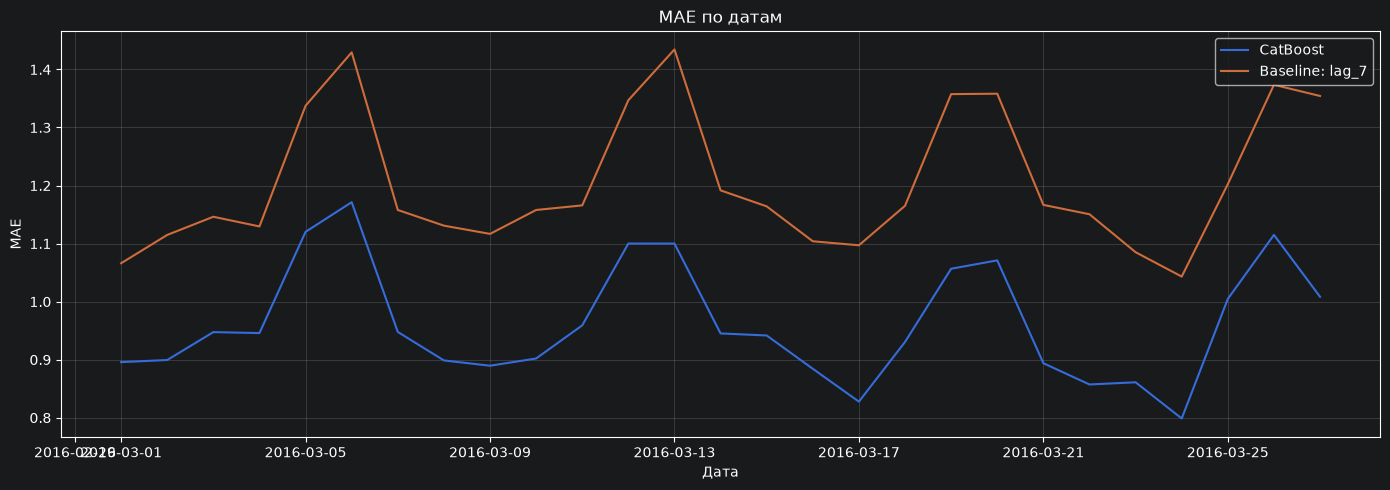

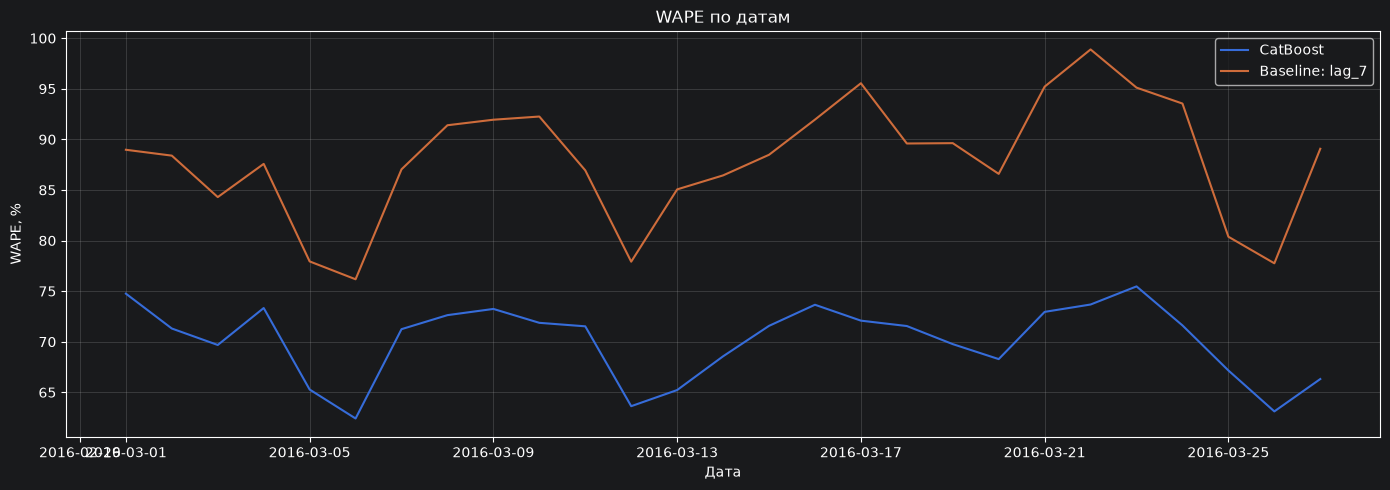

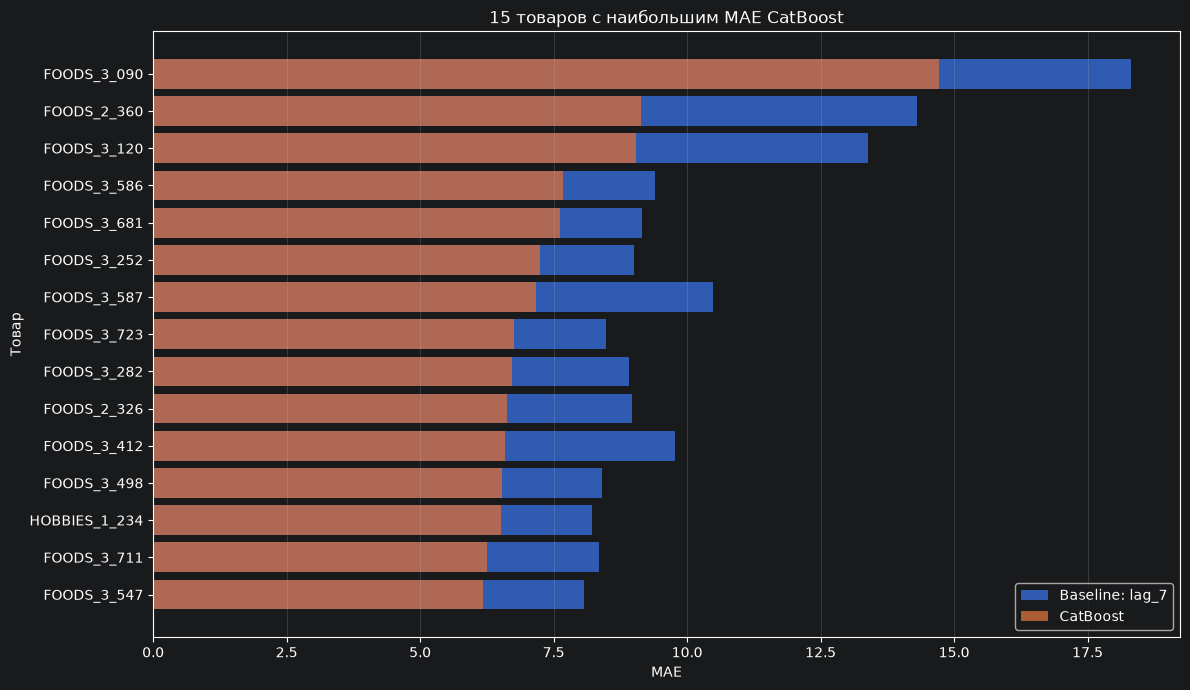

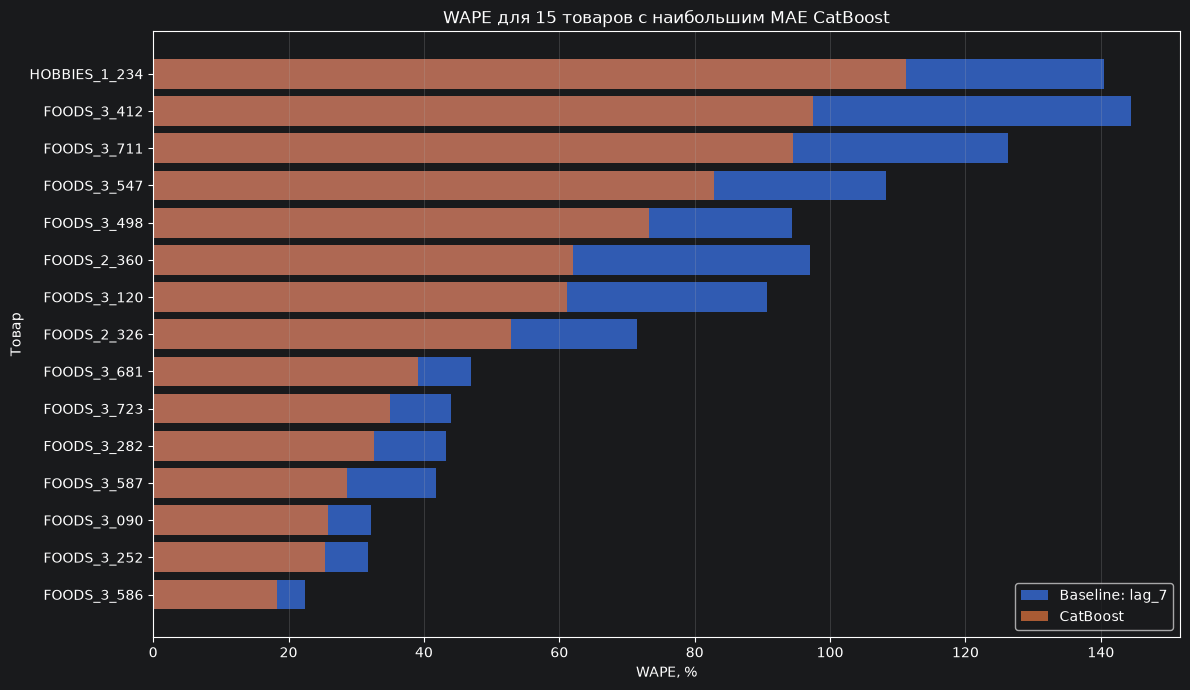

In [71]:
import pandas as pd
import matplotlib.pyplot as plt

# Оставляем строки, где есть фактические продажи и прогнозы обеих моделей
df = errors_df.dropna(
    subset=["sales", "catboost_pred", "baseline_pred"]
).copy()

# Абсолютные ошибки
df["catboost_abs_error"] = (df["catboost_pred"] - df["sales"]).abs()
df["baseline_abs_error"] = (df["baseline_pred"] - df["sales"]).abs()


# ==================================================
# 1. Ошибки по датам
# ==================================================

daily = df.groupby("date").agg(
    n=("sales", "size"),
    actual_sales=("sales", "sum"),
    cb_abs_error=("catboost_abs_error", "sum"),
    base_abs_error=("baseline_abs_error", "sum"),
).reset_index()

daily["date"] = pd.to_datetime(daily["date"])

daily["catboost_mae"] = daily["cb_abs_error"] / daily["n"]
daily["baseline_mae"] = daily["base_abs_error"] / daily["n"]

daily["catboost_wape"] = (
    100 * daily["cb_abs_error"] / daily["actual_sales"].replace(0, float("nan"))
)
daily["baseline_wape"] = (
    100 * daily["base_abs_error"] / daily["actual_sales"].replace(0, float("nan"))
)

daily = daily.sort_values("date")


# График 1: MAE по датам
plt.figure(figsize=(14, 5))
plt.plot(daily["date"], daily["catboost_mae"], label="CatBoost")
plt.plot(daily["date"], daily["baseline_mae"], label="Baseline: lag_7")
plt.title("MAE по датам")
plt.xlabel("Дата")
plt.ylabel("MAE")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# График 2: WAPE по датам
plt.figure(figsize=(14, 5))
plt.plot(daily["date"], daily["catboost_wape"], label="CatBoost")
plt.plot(daily["date"], daily["baseline_wape"], label="Baseline: lag_7")
plt.title("WAPE по датам")
plt.xlabel("Дата")
plt.ylabel("WAPE, %")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ==================================================
# 2. Ошибки по товарам
# ==================================================

items = df.groupby(["item_id", "cat_id", "dept_id"]).agg(
    n=("sales", "size"),
    actual_sales=("sales", "sum"),
    cb_abs_error=("catboost_abs_error", "sum"),
    base_abs_error=("baseline_abs_error", "sum"),
).reset_index()

items["catboost_mae"] = items["cb_abs_error"] / items["n"]
items["baseline_mae"] = items["base_abs_error"] / items["n"]

items["catboost_wape"] = (
    100 * items["cb_abs_error"] / items["actual_sales"].replace(0, float("nan"))
)
items["baseline_wape"] = (
    100 * items["base_abs_error"] / items["actual_sales"].replace(0, float("nan"))
)

# Берём 15 товаров с наибольшим MAE CatBoost
top_items = (
    items.nlargest(15, "catboost_mae")
    .sort_values("catboost_mae")
    .copy()
)

# График 3: MAE для товаров с наибольшей ошибкой CatBoost
plt.figure(figsize=(12, 7))
plt.barh(
    top_items["item_id"],
    top_items["baseline_mae"],
    label="Baseline: lag_7",
    alpha=0.8,
)
plt.barh(
    top_items["item_id"],
    top_items["catboost_mae"],
    label="CatBoost",
    alpha=0.8,
)
plt.title("15 товаров с наибольшим MAE CatBoost")
plt.xlabel("MAE")
plt.ylabel("Товар")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


# График 4: WAPE для тех же товаров
top_wape = top_items.dropna(
    subset=["catboost_wape", "baseline_wape"]
).sort_values("catboost_wape")

plt.figure(figsize=(12, 7))
plt.barh(
    top_wape["item_id"],
    top_wape["baseline_wape"],
    label="Baseline: lag_7",
    alpha=0.8,
)
plt.barh(
    top_wape["item_id"],
    top_wape["catboost_wape"],
    label="CatBoost",
    alpha=0.8,
)
plt.title("WAPE для 15 товаров с наибольшим MAE CatBoost")
plt.xlabel("WAPE, %")
plt.ylabel("Товар")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [74]:
daily_analysis = daily.merge(
    calendar[["date", "weekday", "event_name_1", "event_type_1"]],
    on="date",
    how="left"
)

print(
    daily_analysis[
        [
            "date",
            "weekday",
            "event_name_1",
            "event_type_1",
            "actual_sales",
            "catboost_mae",
            "baseline_mae",
            "catboost_wape",
            "baseline_wape",
        ]
    ].sort_values("catboost_mae", ascending=False).head(10)
)

         date   weekday event_name_1 event_type_1  actual_sales  catboost_mae  \
5  2016-03-06    Sunday          NaN          NaN         57218      1.171296   
4  2016-03-05  Saturday          NaN          NaN         52322      1.120194   
25 2016-03-26  Saturday          NaN          NaN         53863      1.114980   
11 2016-03-12  Saturday          NaN          NaN         52711      1.100070   
12 2016-03-13    Sunday          NaN          NaN         51421      1.100019   
19 2016-03-20    Sunday          NaN          NaN         47825      1.071076   
18 2016-03-19  Saturday          NaN          NaN         46181      1.056665   
26 2016-03-27    Sunday       Easter     Cultural         46360      1.008301   
24 2016-03-25    Friday          NaN          NaN         45611      1.004677   
10 2016-03-11    Friday          NaN          NaN         40887      0.959139   

    baseline_mae  catboost_wape  baseline_wape  
5       1.429485      62.415329      76.173582  
4       1.

     weekday  days  avg_sales  catboost_mae  baseline_mae  catboost_wape  \
1     Monday     3  39985.667         0.929         1.172         70.919   
5    Tuesday     4  37463.750         0.898         1.128         73.158   
6  Wednesday     4  36720.500         0.884         1.105         73.418   
4   Thursday     4  37184.500         0.869         1.111         71.312   
0     Friday     4  41368.750         0.960         1.166         70.892   
2   Saturday     4  51269.250         1.098         1.354         65.447   
3     Sunday     4  50706.000         1.088         1.394         65.560   

   baseline_wape  
1         89.564  
5         91.933  
6         91.850  
4         91.410  
0         86.121  
2         80.808  
3         84.223  


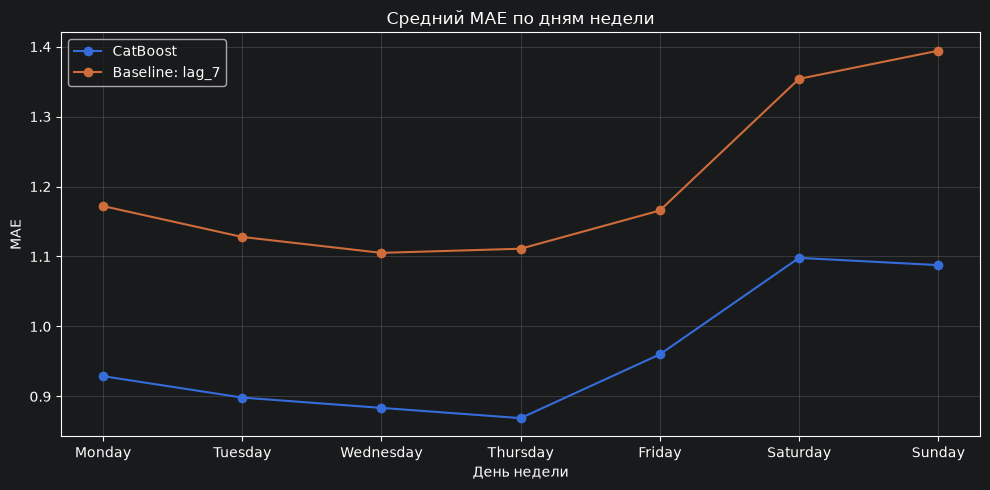

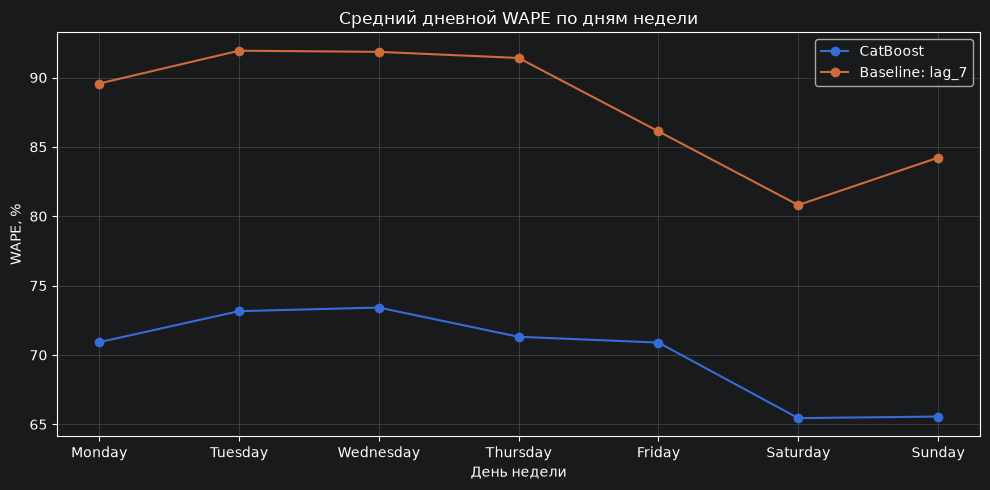

In [77]:
daily_analysis["weekday"] = pd.to_datetime(
    daily_analysis["date"]
).dt.day_name()

weekday_metrics = daily_analysis.groupby("weekday").agg(
    days=("date", "count"),
    avg_sales=("actual_sales", "mean"),
    catboost_mae=("catboost_mae", "mean"),
    baseline_mae=("baseline_mae", "mean"),
    catboost_wape=("catboost_wape", "mean"),
    baseline_wape=("baseline_wape", "mean"),
).reset_index()

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_metrics["weekday"] = pd.Categorical(
    weekday_metrics["weekday"],
    categories=weekday_order,
    ordered=True
)

weekday_metrics = weekday_metrics.sort_values("weekday")

print(weekday_metrics.round(3))
import matplotlib.pyplot as plt

# MAE по дням недели
plt.figure(figsize=(10, 5))
plt.plot(
    weekday_metrics["weekday"].astype(str),
    weekday_metrics["catboost_mae"],
    marker="o",
    label="CatBoost"
)
plt.plot(
    weekday_metrics["weekday"].astype(str),
    weekday_metrics["baseline_mae"],
    marker="o",
    label="Baseline: lag_7"
)
plt.title("Средний MAE по дням недели")
plt.xlabel("День недели")
plt.ylabel("MAE")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# WAPE по дням недели
plt.figure(figsize=(10, 5))
plt.plot(
    weekday_metrics["weekday"].astype(str),
    weekday_metrics["catboost_wape"],
    marker="o",
    label="CatBoost"
)
plt.plot(
    weekday_metrics["weekday"].astype(str),
    weekday_metrics["baseline_wape"],
    marker="o",
    label="Baseline: lag_7"
)
plt.title("Средний дневной WAPE по дням недели")
plt.xlabel("День недели")
plt.ylabel("WAPE, %")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

                   feature  importance
18          rolling_mean_7   23.210649
15                   lag_1   14.348593
20         rolling_mean_28   11.704325
19         rolling_mean_14    9.865146
6                     wday    6.500849
30  avg_positive_demand_14    4.104910
17                  lag_28    3.791035
10            day_of_month    3.172647
16                   lag_7    3.089386
0                  item_id    2.646533
9             week_of_year    2.380029
3             event_name_1    1.982976
2                 store_id    1.667000
27         nonzero_days_14    1.322127
1                  dept_id    1.305526
13                 snap_WI    1.151101
21          rolling_std_28    0.994228
31                  adi_14    0.818945
29         nonzero_rate_14    0.806683
24         price_median_28    0.750557


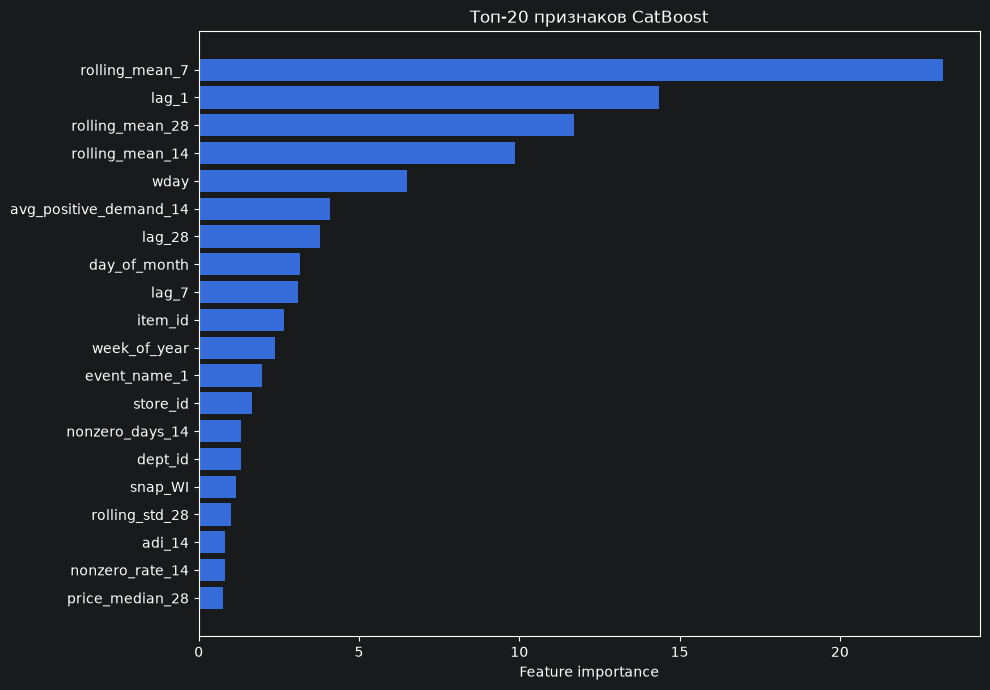

In [80]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model.get_feature_importance()
}).sort_values("importance", ascending=False)

print(importance.head(20))

top_features = importance.head(20).sort_values("importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["feature"], top_features["importance"])
plt.title("Топ-20 признаков CatBoost")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

In [81]:
regime_metrics = errors_df.groupby("demand_regime_14").apply(
    lambda g: pd.Series({
        "observations": len(g),
        "actual_sales": g["sales"].sum(),
        "MAE": g["catboost_abs_error"].mean(),
        "RMSE": (
            (g["catboost_pred"] - g["sales"]) ** 2
        ).mean() ** 0.5,
        "Bias": (
            g["catboost_pred"] - g["sales"]
        ).mean(),
        "WAPE_%": (
            100 * g["catboost_abs_error"].sum()
            / g["sales"].abs().sum()
            if g["sales"].abs().sum() > 0 else float("nan")
        ),
    })
).reset_index()

print(regime_metrics.round(3))

  demand_regime_14  observations  actual_sales    MAE   RMSE   Bias   WAPE_%
0     intermittent      473956.0      181848.0  0.490  1.093 -0.023  127.586
1          regular      349274.0      956960.0  1.603  2.803 -0.085   58.509


In [ ]:

### Baseline - seasonal forecast
def seasonal_naive_forecast(
    train_df,
    horizon=28,
    season_length=7
):
    """
    Seasonal Naive forecast для одной временной серии.
    train_df: DataFrame с колонками date и sales

    horizon: горизонт прогноза в днях.
    season_length: длина сезонности. Для недельной сезонности = 7.
    """
    if train_df['item_id'].nunique()==1 and train_df['store_id'].nunique()==1:
        item_id = train_df['item_id'].unique()[0]
        store_id = train_df['store_id'].unique()[0]
        train_df = train_df.sort_values(by ='date' ).copy()
        diff = (train_df['date'] - train_df['date'].shift(1)).dt.days
        last_date = train_df['date'].iloc[-1]
        future_dates = pd.date_range(start=last_date+pd.Timedelta(days = 1), end=last_date + pd.Timedelta(days=horizon))

        if diff.max(skipna=True)==1 and diff.min(skipna=True)==1:

            df = pd.DataFrame([])
            s = pd.Series([])
            df['forecast_dates'] = future_dates
            df['item_id'] = item_id
            df['store_id'] = store_id
            if season_length < horizon:
                while len(s)< horizon:
                    s = pd.concat([s, train_df.tail(season_length)['sales']])
                df['forecast_sales'] = s[0:horizon].reset_index(drop=True)

            elif season_length >= horizon:
                df['forecast_sales'] = train_df.tail(season_length )[0:horizon]['sales']


        else:
            raise ValueError("additional preprocessing is required for the calendar")
    else:
        raise ValueError('Input train_df must contain exactly one item_id and one store_id')

    return df

all_forecast = []
for (item_id, store_id), group in train_df.groupby(['item_id','store_id']):
    forecast_df = seasonal_naive_forecast(
        train_df=group, horizon=28,
        season_length=7)
    all_forecast.append(forecast_df)
forecasts_df = pd.concat(all_forecast, ignore_index=True)


baseline_forecast = test_df.merge(forecasts_df, how='left', left_on=['item_id','store_id','date'], right_on = ['item_id','store_id','forecast_dates'])
print(baseline_forecast[['item_id','store_id','date','sales','forecast_dates','forecast_sales']].head(10))
if baseline_forecast['forecast_sales'].isna().sum() == 0:
        print('OK with NA')
else: print( 'Please Check NA values in forecast sales')

mae = (baseline_forecast['sales'] - baseline_forecast['forecast_sales']).abs().mean()
print('MAE of baseline = ', round(mae,2))
rmse = (((baseline_forecast['sales'] - baseline_forecast['forecast_sales'])**2).mean())**0.5
print('RMSE of baseline = ', round(rmse,2))

In [ ]:
## Now we prepare for the modeling. I'm gonna use single model of CatBoost to predict all horizons. So at first we need to
def make_direct_training_data(df, horizon = 28):
    training_parts = []
    if df['item_id'].nunique()==1 and df['store_id'].nunique()==1:
        for hor in range(1, horizon+1):
            tmp = df.copy()
            tmp['horizon'] = hor
            tmp['target'] = tmp['sales'].shift(-hor)
            tmp['target_date'] = tmp['date'].shift(-hor)
            tmp = tmp.dropna(subset=['target'])
            training_parts.append(tmp)
        training_df = pd.concat(training_parts, ignore_index = True)
    else:
        raise ValueError('Input df must contain exactly one item_id and one store_id')
    return training_df


train_help = []
for (item_id, store_id), group in train_window.groupby(['item_id','store_id']):
    tmp = make_direct_training_data(group, horizon = 28)
    train_help.append(tmp)
training_df = pd.concat(train_help, ignore_index = True)
del train_help

print(training_df.head())
print(training_df['horizon'].value_counts().sort_index())
print(training_df['target'].isna().sum())


In [ ]:
#### We take only nessesary columns from the training dataset. and only 5M of rows due to limitations of memory

X_train = training_df[feature_cols].reset_index(drop = True)
y_train = training_df['target'].reset_index(drop = True)

rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_train),size=5_000_000,replace=False)

X_train_sample = X_train.iloc[sample_idx].copy()
y_train_sample = y_train.iloc[sample_idx].copy()

# NaN в категориальных признаках
X_train_sample['event_name_1'] = (X_train_sample['event_name_1'].fillna('None').astype(str))

print(X_train_sample[cat_features].isna().sum())


In [ ]:
### Here we prepare features for validation

# Origin_date is the last date when we assume that we know sales. It is the last day of train_window
origin_date = training_df['date'].max()
origins = training_df[training_df['date'] == origin_date].copy()


## Features known for the whole validation period which describe state in the future (prices, holidays...)
future_features = validation_df[
    [   'item_id','dept_id','store_id',
        'date','wday','month','year','week_of_year', 'day_of_month',
        'snap',
        'sell_price',
        'event_name_1','event_type_1',
        'days_after_release']].rename(columns={'date': 'target_date'}).copy()
## Features known for every item*store at the moment of origins (1 raw per each item*store )
history_features = origins[
       ['item_id','store_id',
        'lag1','lag7','lag28',
        'rolling_mean7','rolling_mean28','rolling_median28',
        'rolling_std7','rolling_std28',
        'price1','price7','price28',
        'trend',
        'discount1','discount7','discount28']].copy()

###### Now we combine the same structure as the dataframe with ll features, but some of them we know at the origin_date, and others are spread in future with known future characteristics
validation_features = future_features.merge(history_features,how='left',on=['item_id', 'store_id'])
## We determine horizon which is needed for the single CatBoost model
validation_features['horizon'] = (validation_features['target_date'] - origin_date).dt.days
X_validation = validation_features[feature_cols].copy()


for col in cat_features:
    X_validation[col] = X_validation[col].fillna('None')
    X_train_sample[col] = X_train_sample[col].fillna('None')

print('X_train_sample:', X_train_sample.shape)
print('X_validation:', X_validation.shape)

In [ ]:
### We prepared everything for building a model, so let's go


from catboost import CatBoostRegressor
import numpy as np
import pandas as pd

# Quantiles we want to predict
quantiles = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

models = {}
forecasts = {}

for q in quantiles:
    model = CatBoostRegressor(
        loss_function=f'Quantile:alpha={q}',
        eval_metric='MAE',
        iterations=500,
        learning_rate=0.05,
        depth=8,
        random_seed=42,
        verbose=100
    )

    model.fit(
        X_train_sample,
        y_train_sample,
        cat_features=cat_features
    )

    models[q] = model
    forecasts[q] = model.predict(X_validation)

# Combine all quantile forecasts into one dataframe
validation_features = validation_features.copy()

for q in quantiles:
    validation_features[f'forecast_p{int(q * 100)}'] = forecasts[q]

validation_features[
    ['item_id', 'store_id', 'target_date', 'horizon',
     'forecast_p20', 'forecast_p30', 'forecast_p40',
     'forecast_p50', 'forecast_p60', 'forecast_p70',
     'forecast_p80']
].head(10)


### Now we combine the prediction and the actuals
def pinball_loss(y_true, y_pred, q):
    errors = y_true - y_pred
    return np.maximum(q * errors, (q - 1) * errors).mean()


# Join actual sales to forecasts
validation_result = validation_features[
    ['item_id', 'store_id', 'target_date', 'horizon'] +
    [f'forecast_p{int(q * 100)}' for q in quantiles]
].merge(
    validation_df[['item_id', 'store_id', 'date', 'sales']],
    how='left',
    left_on=['item_id', 'store_id', 'target_date'],
    right_on=['item_id', 'store_id', 'date']
).rename(columns={'sales': 'actual'})

# Evaluate each quantile
results = []

for q in quantiles:
    col = f'forecast_p{int(q * 100)}'

    results.append({
        'quantile': f'P{int(q * 100)}',
        'MAE': (validation_result['actual'] -
                validation_result[col]).abs().mean(),
        'Pinball loss': pinball_loss(
            validation_result['actual'],
            validation_result[col],
            q
        ),
        'Coverage': (
            validation_result['actual'] <=
            validation_result[col]
        ).mean()
    })

metrics = pd.DataFrame(results)
print(metrics.round(3))


In [ ]:
### Now we are looking for the best parameter using grid iterations*depth

iterations_list = [500, 1000, 1500]
depth_list = [6, 8, 10]

results = []

for iterations in iterations_list:
    for depth in depth_list:

        print(f'\nTraining: iterations={iterations}, depth={depth}')

        model = CatBoostRegressor(
            loss_function='RMSE',
            eval_metric='MAE',
            iterations=iterations,
            learning_rate=0.05,
            depth=depth,
            random_seed=42,
            verbose=False
        )

        model.fit(
            X_train_sample,
            y_train_sample,
            cat_features=cat_features
        )

        forecast = model.predict(X_validation)

        mae = (
            validation_result['actual'] - forecast
        ).abs().mean()

        rmse = np.sqrt(
            ((validation_result['actual'] - forecast) ** 2).mean()
        )

        results.append({
            'iterations': iterations,
            'depth': depth,
            'MAE': mae,
            'RMSE': rmse
        })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values('MAE')

print(results_df)
# Training: iterations=1500, depth=10
#    iterations  depth       MAE      RMSE
# 3        1000      6  1.063566  2.282704
# 6        1500      6  1.065099  2.288695
# 0         500      6  1.065220  2.282283
# 2         500     10  1.066018  2.292545
# 1         500      8  1.068164  2.284326
# 5        1000     10  1.070801  2.304752
# 7        1500      8  1.073315  2.296634
# 8        1500     10  1.074646  2.314555
# 4        1000      8  1.075338  2.289589